# Case A SMT example models

This figure is to show the effect of partial stripping on the WR phase.

In [1]:
# Open Zsun, 0.45, 0.1 Zsun grids

from posydon.grids.psygrid import PSyGrid
from posydon.config import PATH_TO_POSYDON_DATA
from posydon.utils.common_functions import convert_metallicity_to_string, orbital_separation_from_period
from posydon.popsyn.distributions import PowerLawPeriod
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from cmap import Colormap
import pickle
from pathlib import Path
from tqdm import tqdm
from scipy.stats import gaussian_kde
from helper_functions import calc_Teff, optical_depth_calculation


tol_vibrant = Colormap('tol:vibrant')(np.linspace(0, 1, 7))

# detailed model paths:
grid_Zsun = PSyGrid('/srv/astro/projects/posydon/running_grids/POSYDON_GRIDS_v2/HMS-HMS/1e+00_Zsun/ORIGINAL/grid_low_res_ext_combined_rerun8C_dedt_hepulse.h5')
print("grid_Zsun loaded")
grid_045Zsun = PSyGrid('/srv/astro/projects/posydon/running_grids/POSYDON_GRIDS_v2/HMS-HMS/4.5e-01_Zsun/ORIGINAL/grid_low_res_ext_combined_rerun8C_dedt_hepulse.h5')
print("grid_045Zsun loaded")
grid_01Zsun = PSyGrid('/srv/astro/projects/posydon/running_grids/POSYDON_GRIDS_v2/HMS-HMS/1e-01_Zsun/ORIGINAL/grid_low_res_ext_combined_rerun8C_dedt_hepulse.h5')
print("grid_01Zsun loaded")

grid_Zsun loaded
grid_045Zsun loaded
grid_01Zsun loaded


In [11]:
period_value =  1.00000000e+01 # days
M1_value = 44.77441597 # Msun
q_value = 0.8 # M2/M1
M2_value = M1_value * q_value

print(f"Period: {period_value} days, M1: {M1_value} Msun, M2: {M2_value} Msun")

Period: 10.0 days, M1: 44.77441597 Msun, M2: 35.819532776 Msun


In [12]:
# in Zsun find the closest model to the given period, M1, and M2

Zsun_data = grid_Zsun.initial_values[['period_days', "star_1_mass", "star_2_mass"]]
# print(np.unique(Zsun_data['period_days']))
# print(np.unique(Zsun_data['star_1_mass']))
# print(np.unique(Zsun_data['star_2_mass']))


# Find the closest model in Zsun grid
P_mask = np.isclose(Zsun_data['period_days'], period_value, atol=0.1)
M1_mask = np.isclose(Zsun_data['star_1_mass'], M1_value, atol=1)
M2_mask = np.isclose(Zsun_data['star_2_mass'], M2_value, atol=1)

model_id = np.where(P_mask & M1_mask & M2_mask)[0][0]
Zsun_model = grid_Zsun[model_id]

Zsun045_data = grid_045Zsun.initial_values[['period_days', "star_1_mass", "star_2_mass"]]
# Find the closest model in 0.45 Zsun grid
P_mask_045 = np.isclose(Zsun045_data['period_days'], period_value, atol=0.1)
M1_mask_045 = np.isclose(Zsun045_data['star_1_mass'], M1_value, atol=1)
M2_mask_045 = np.isclose(Zsun045_data['star_2_mass'], M2_value, atol=1)

model_id_045 = np.where(P_mask_045 & M1_mask_045 & M2_mask_045)[0][0]
Zsun045_model = grid_045Zsun[model_id_045]

# 01 Zsun data
Zsun01_data = grid_01Zsun.initial_values[['period_days', "star_1_mass", "star_2_mass"]]
# Find the closest model in 0.1 Zsun grid
P_mask_01 = np.isclose(Zsun01_data['period_days'], period_value, atol=0.1)
M1_mask_01 = np.isclose( Zsun01_data['star_1_mass'], M1_value, atol=1)
M2_mask_01 = np.isclose( Zsun01_data['star_2_mass'], M2_value, atol=1)

model_id_01 = np.where(P_mask_01 & M1_mask_01 & M2_mask_01)[0][0]
Zsun01_model = grid_01Zsun[model_id_01]


In [13]:
def classify_WR(d):
    """Return WNL, WNE, WC boolean masks for a data dict from load_metallicity."""
    WNL = (
        (d['surface_H'] > 0.05) & (d['surface_H'] <= 0.5)
        & (d['optical_depth'] > 1.5)
        & ~pd.Series(d['S1_state']).str.contains('H_burning', na=False).values
    )
    WNE = (d['surface_H'] <= 0.05) & (d['surface_He'] >= 0.7) & (d['optical_depth'] > 1.5)
    WC  = (d['surface_H'] <= 0.05) & (d['surface_He'] <  0.7) & (d['optical_depth'] > 1.5)
    return WNL, WNE, WC

420534.27120664995
[37.66442816 37.66365188 37.66287724 37.66210315 37.66132963 37.66055684
 37.65978602 37.65901577 37.65824636 37.65706954 37.65563535 37.65344857
 37.65069381 37.64749052 37.64381175 37.64001214 37.63601214 37.63178801
 37.62699514 37.62157954 37.61563999 37.60951212 37.60278125 37.59569676
 37.5883526  37.58068928 37.57198443 37.56295474 37.55369486 37.54410466
 37.53411893 37.52369387 37.51328407 37.50288076 37.49247963 37.48207716
 37.4716707  37.46125907 37.45084201 37.44041914 37.4299887  37.41955134
 37.4091062  37.39865276 37.38819095 37.3777219  37.36724459 37.3567583
 37.34626395 37.33576185 37.3252504  37.3147302  37.30421389 37.28486179
 37.26658535 37.2437732  37.21813928 37.18178052 37.12927621 37.04046718
 36.95157332 36.85461345 36.74131881 36.62603908 36.51375146 36.36866118
 36.19802636 35.99338345 35.7847558  35.57756463 35.35677552 35.13571874
 34.92532294 34.72358675 34.49798968 34.36429466 34.21260407 34.01193612
 33.89130012 33.75547486 33.57355

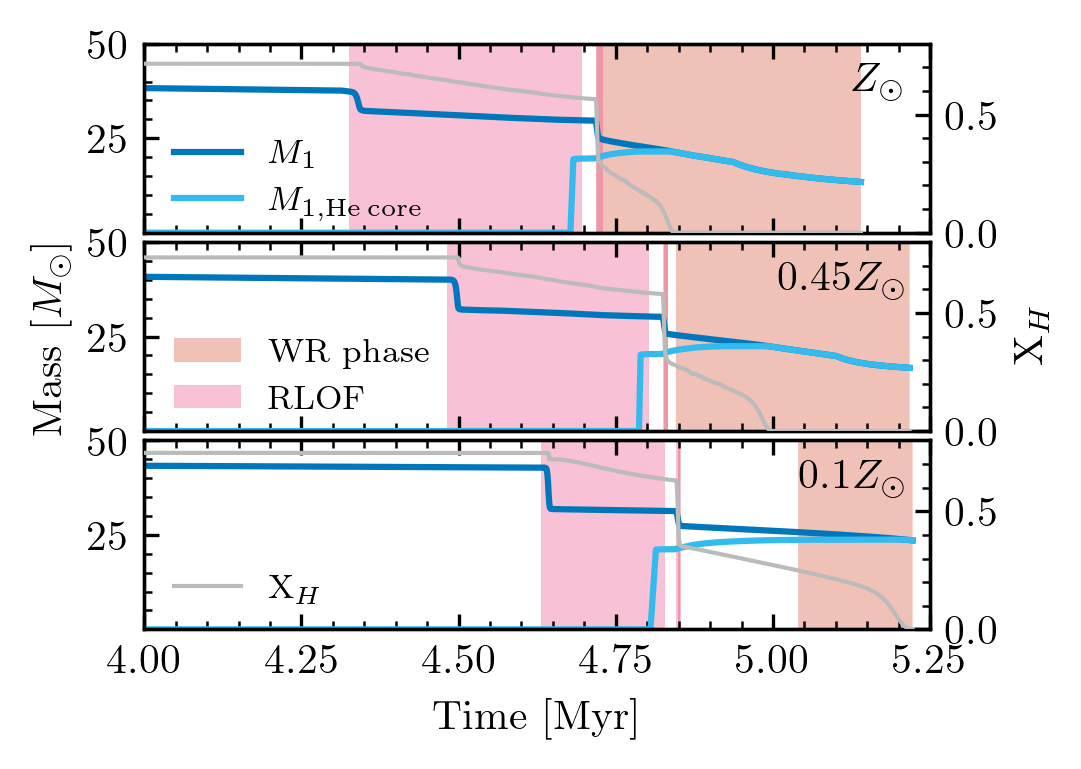

In [ ]:

# plot the evolution of the model

import os


fig, axes = plt.subplots(3, 1, figsize=(3.38, 2.535))

axes[0].plot(Zsun_model.binary_history['age']/1e6, Zsun_model.binary_history['star_1_mass'], label=r'$M_1$', color=tol_vibrant[0])
axes[0].plot(Zsun_model.binary_history['age']/1e6, Zsun_model.history1['he_core_mass'], label=r'$M_{1,\mathrm{He\, core}}$', color=tol_vibrant[1])

axes[1].plot(Zsun045_model.binary_history['age']/1e6, Zsun045_model.binary_history['star_1_mass'], label=r'$M_1$', color=tol_vibrant[0])
axes[1].plot(Zsun045_model.binary_history['age']/1e6, Zsun045_model.history1['he_core_mass'], label=r'$M_{1,\mathrm{He\, core}}$', color=tol_vibrant[1])

axes[2].plot(Zsun01_model.binary_history['age']/1e6, Zsun01_model.binary_history['star_1_mass'], label=r'$M_1$', color=tol_vibrant[0])
axes[2].plot(Zsun01_model.binary_history['age']/1e6, Zsun01_model.history1['he_core_mass'], label=r'$M_{1,\mathrm{He\, core}}$', color=tol_vibrant[1])


labels = ['Zsun', '0.45Zsun', '0.1Zsun']
# calculate the optical depth for each model
optical_depth = {}
for model, label in zip([Zsun_model, Zsun045_model, Zsun01_model], labels):
    optical_depth[label] = optical_depth_calculation(M=model.binary_history['star_1_mass'],
                                                                      R=10**model.history1['log_R'],
                                                                      L=10**model.history1['log_L'],
                                                                      Mdot=10**model.binary_history['lg_mstar_dot_1'],
                                                                      surface_H=model.history1['surface_h1'],
                                                                      surface_He=model.history1['surface_he4'],
                                                                      Teff = 10**model.history1['log_Teff'],)

# Separate y-axis on the right side for the optical depth
# for i, model in enumerate([Zsun_model, Zsun045_model, Zsun01_model]):
#     ax = axes[i]
#     ax2 = ax.twinx()
#     ax2.plot(model.binary_history['age']/1e6, optical_depth[list(optical_depth.keys())[i]], color=tol_vibrant[5], zorder=5, label=r'$\tau$', lw=1)
#     ax2.axhline(1.5, color=tol_vibrant[5], ls='--', lw=1, label=r'$\tau = 1.5$', alpha=0.3)
#     ax2.set_ylabel(r'$\tau$', color=tol_vibrant[5])
#     ax2.tick_params(axis='y', labelcolor=tol_vibrant[5])
#     ax2.set_ylim(0.001, 10)


for i, model in enumerate([Zsun_model, Zsun045_model, Zsun01_model]):
    # WNE, WNL, WC masks

    WNL = (
        (model.history1['surface_h1'] > 0.05) & (model.history1['surface_h1'] <= 0.5)
        & (optical_depth[list(optical_depth.keys())[i]] > 1.5)
       #& ~pd.Series(model.binary_history['S1_state']).str.contains('H_burning', na=False).values
    )
    WNE = (model.history1['surface_h1'] <= 0.05) & (model.history1['surface_he4'] >= 0.7) & (optical_depth[list(optical_depth.keys())[i]] > 1.5)
    WC  = (model.history1['surface_h1'] <= 0.05) & (model.history1['surface_he4'] <  0.7) & (optical_depth[list(optical_depth.keys())[i]] > 1.5)

    axes[i].fill_between(model.binary_history['age']/1e6, 0, 50, where=(WNL | WNE | WC), color=tol_vibrant[4], alpha=0.3, label='WR phase',edgecolor=None )
    # calculate WR durattion
    if np.any(WNL | WNE | WC):
        WR_duration = model.binary_history['age'][WNL | WNE | WC][-1] - model.binary_history['age'][WNL | WNE | WC][0]
        print(WR_duration)
    else: 
        WR_duration = 0
        print(WR_duration)
    
    axes[i].set_ylim(0.0001, 50)
    axes[i].set_xlim(4, 5.25)
    
    start_id = np.where(model.binary_history['rl_relative_overflow_1'] > -0.05)[0]
    final_id = np.where(model.binary_history['rl_relative_overflow_1'] > -0.01)[0][-1]
    
    print(model.binary_history['star_1_mass'][start_id])
    print(model.history1['he_core_mass'][start_id])
    print(model.binary_history['star_1_mass'][start_id] - model.history1['he_core_mass'][start_id])
    #for k in start_id:
    #    axes[i].axvline(model.binary_history['age'][k]/1e6, 0, 50, color='black', alpha=1,lw=1, zorder=10, ls='--')
    print(model.binary_history['star_1_mass'][final_id])
    print(model.history1['he_core_mass'][final_id])
    print(model.binary_history['star_1_mass'][final_id] - model.history1['he_core_mass'][final_id])
    
    #print(model.binary_history['age'][start_id]/1e6)
    
    axes[i].fill_between(model.binary_history['age']/1e6, 0, 50, where=(model.binary_history['rl_relative_overflow_1'] > -0.01), color=tol_vibrant[5], alpha=0.3, label='RLOF', edgecolor=None)
    
    # plot a second y-axis for the roche lobe filling factor
    ax2 = axes[i].twinx()
    #ax2.axhline(0.4, color=tol_vibrant[6], ls='--', lw=1, label=r'$R_1/R_{L,1} = 0.4$', alpha=0.3)
    ax2.plot(model.binary_history['age']/1e6, model.history1['surface_h1'], color=tol_vibrant[6], zorder=5, label=r'$\mathrm{X}_H$', lw=1)
    if i == 1:
        ax2.set_ylabel(r'$\mathrm{X}_H$')
    ax2.set_ylim(0, 0.8)

# build 2 legends
# legend 1 in axes[0]: M1 and He Core only
handles0, labels0 = axes[0].get_legend_handles_labels()
filtered0 = [(h, l) for h, l in zip(handles0, labels0) if l in [r'$M_1$', r'$M_{1,\mathrm{He\, core}}$']]
axes[0].legend([h for h, l in filtered0], [l for h, l in filtered0],
               bbox_to_anchor=(0.0, 0.65), loc='upper left', ncol=1)

# legend 2 in axes[1]: WR phase and RLOF only
handles1, labels1 = axes[1].get_legend_handles_labels()
filtered1 = [(h, l) for h, l in zip(handles1, labels1) if l in ['WR phase', 'RLOF']]
axes[1].legend([h for h, l in filtered1], [l for h, l in filtered1],
               bbox_to_anchor=(0.0, 0.65), loc='upper left', ncol=1)

handles2, labels2 = ax2.get_legend_handles_labels()
filtered2 = [(h, l) for h, l in zip(handles2, labels2) if l in [r'$\mathrm{X}_H$']]
axes[2].legend([h for h, l in filtered2], [l for h, l in filtered2], 
               bbox_to_anchor=(0.0, 0.45), loc='upper left', ncol=1)


plt.subplots_adjust(hspace=0.05)

axes[0].set_xticklabels([])
axes[1].set_xticklabels([])
    
axes[1].set_ylabel('Mass [$M_\odot$]')
axes[2].set_xlabel('Time [Myr]')

axes[0].text(0.97, 0.75, '$Z_\odot$', transform=axes[0].transAxes, ha='right')
axes[1].text(0.97, 0.75, '$0.45 Z_\odot$', transform=axes[1].transAxes, ha='right')
axes[2].text(0.97, 0.75, '$0.1 Z_\odot$', transform=axes[2].transAxes, ha='right')

figure_folder = '.'
os.makedirs(f"{figure_folder}/png", exist_ok=True)
os.makedirs(f"{figure_folder}/pdf", exist_ok=True)

plt.savefig(f"{figure_folder}/png/Case_A_WR_evolution_Zsun_045Zsun_01Zsun.png", dpi=300, bbox_inches='tight')
plt.savefig(f"{figure_folder}/pdf/Case_A_WR_evolution_Zsun_045Zsun_01Zsun.pdf", dpi=300, bbox_inches='tight')
plt.show()

# Case B SMT example models

This figure is to show the effect of partial stripping on the WR phase.

In [6]:
period_value = 3.72759372e+02 # days
M1_value = 44.77441597 # Msun
q_value = 0.8 # M2/M1
M2_value = M1_value * q_value

print(f"Period: {period_value} days, M1: {M1_value} Msun, M2: {M2_value} Msun")

Period: 372.759372 days, M1: 44.77441597 Msun, M2: 35.819532776 Msun


In [7]:
# in Zsun find the closest model to the given period, M1, and M2

Zsun_data = grid_Zsun.initial_values[['period_days', "star_1_mass", "star_2_mass"]]
# print(np.unique(Zsun_data['period_days']))
# print(np.unique(Zsun_data['star_1_mass']))
# print(np.unique(Zsun_data['star_2_mass']))


# Find the closest model in Zsun grid
P_mask = np.isclose(Zsun_data['period_days'], period_value, atol=0.1)
M1_mask = np.isclose(Zsun_data['star_1_mass'], M1_value, atol=1)
M2_mask = np.isclose(Zsun_data['star_2_mass'], M2_value, atol=1)

model_id = np.where(P_mask & M1_mask & M2_mask)[0][0]
Zsun_model = grid_Zsun[model_id]

Zsun045_data = grid_045Zsun.initial_values[['period_days', "star_1_mass", "star_2_mass"]]
# Find the closest model in 0.45 Zsun grid
P_mask_045 = np.isclose(Zsun045_data['period_days'], period_value, atol=0.1)
M1_mask_045 = np.isclose(Zsun045_data['star_1_mass'], M1_value, atol=1)
M2_mask_045 = np.isclose(Zsun045_data['star_2_mass'], M2_value, atol=1)

model_id_045 = np.where(P_mask_045 & M1_mask_045 & M2_mask_045)[0][0]
Zsun045_model = grid_045Zsun[model_id_045]

# 01 Zsun data
Zsun01_data = grid_01Zsun.initial_values[['period_days', "star_1_mass", "star_2_mass"]]
# Find the closest model in 0.1 Zsun grid
P_mask_01 = np.isclose(Zsun01_data['period_days'], period_value, atol=0.1)
M1_mask_01 = np.isclose( Zsun01_data['star_1_mass'], M1_value, atol=1)
M2_mask_01 = np.isclose( Zsun01_data['star_2_mass'], M2_value, atol=1)

model_id_01 = np.where(P_mask_01 & M1_mask_01 & M2_mask_01)[0][0]
Zsun01_model = grid_01Zsun[model_id_01]


In [8]:
def classify_WR(d):
    """Return WNL, WNE, WC boolean masks for a data dict from load_metallicity."""
    WNL = (
        (d['surface_H'] > 0.05) & (d['surface_H'] <= 0.5)
        & (d['optical_depth'] > 1.5)
        & ~pd.Series(d['S1_state']).str.contains('H_burning', na=False).values
    )
    WNE = (d['surface_H'] <= 0.05) & (d['surface_He'] >= 0.7) & (d['optical_depth'] > 1.5)
    WC  = (d['surface_H'] <= 0.05) & (d['surface_He'] <  0.7) & (d['optical_depth'] > 1.5)
    return WNL, WNE, WC

393634.2844472667
29.390769009399726
20.496384346711473
8.894384662688253
376520.08709108364
29.13177525349586
21.469097256167416
7.662677997328444
0
29.771372523391026
22.17708391176258
7.594288611628446


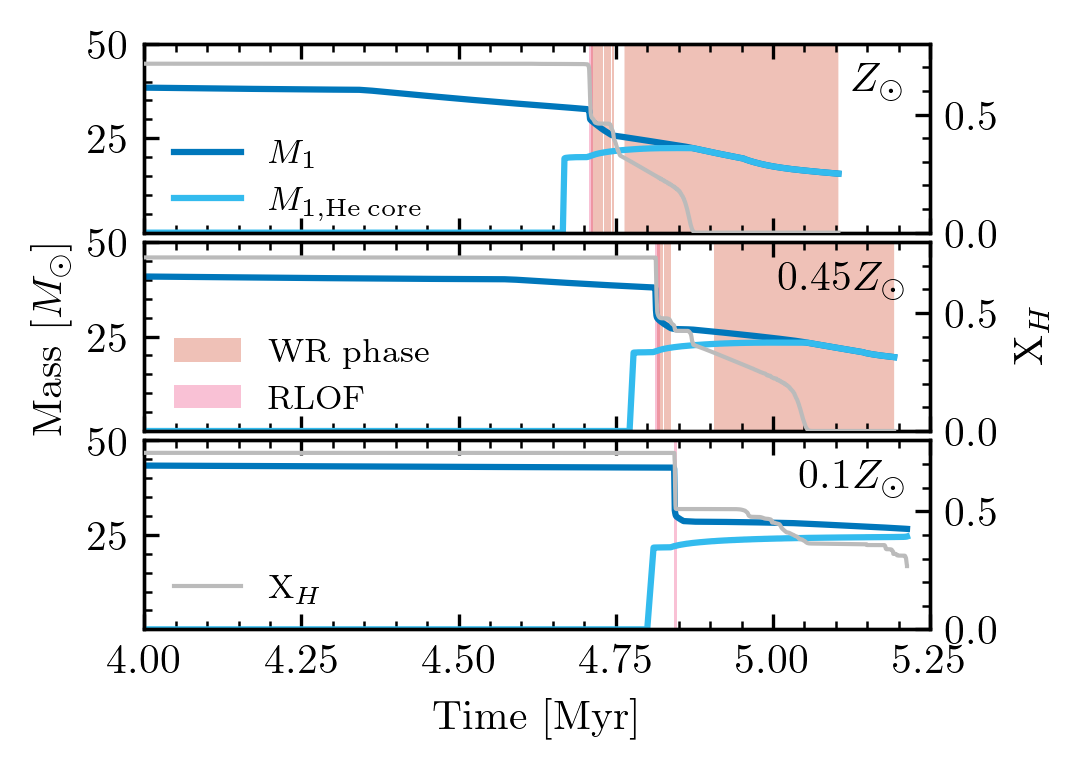

In [9]:

# plot the evolution of the model

import os


fig, axes = plt.subplots(3, 1, figsize=(3.38, 2.535))

axes[0].plot(Zsun_model.binary_history['age']/1e6, Zsun_model.binary_history['star_1_mass'], label=r'$M_1$', color=tol_vibrant[0])
axes[0].plot(Zsun_model.binary_history['age']/1e6, Zsun_model.history1['he_core_mass'], label=r'$M_{1,\mathrm{He\, core}}$', color=tol_vibrant[1])

axes[1].plot(Zsun045_model.binary_history['age']/1e6, Zsun045_model.binary_history['star_1_mass'], label=r'$M_1$', color=tol_vibrant[0])
axes[1].plot(Zsun045_model.binary_history['age']/1e6, Zsun045_model.history1['he_core_mass'], label=r'$M_{1,\mathrm{He\, core}}$', color=tol_vibrant[1])

axes[2].plot(Zsun01_model.binary_history['age']/1e6, Zsun01_model.binary_history['star_1_mass'], label=r'$M_1$', color=tol_vibrant[0])
axes[2].plot(Zsun01_model.binary_history['age']/1e6, Zsun01_model.history1['he_core_mass'], label=r'$M_{1,\mathrm{He\, core}}$', color=tol_vibrant[1])


labels = ['Zsun', '0.45Zsun', '0.1Zsun']
# calculate the optical depth for each model
optical_depth = {}
for model, label in zip([Zsun_model, Zsun045_model, Zsun01_model], labels):
    optical_depth[label] = optical_depth_calculation(M=model.binary_history['star_1_mass'],
                                                                      R=10**model.history1['log_R'],
                                                                      L=10**model.history1['log_L'],
                                                                      Mdot=10**model.binary_history['lg_mstar_dot_1'],
                                                                      surface_H=model.history1['surface_h1'],
                                                                      surface_He=model.history1['surface_he4'],
                                                                      Teff = 10**model.history1['log_Teff'],)

# Separate y-axis on the right side for the optical depth
# for i, model in enumerate([Zsun_model, Zsun045_model, Zsun01_model]):
#     ax = axes[i]
#     ax2 = ax.twinx()
#     ax2.plot(model.binary_history['age']/1e6, optical_depth[list(optical_depth.keys())[i]], color=tol_vibrant[5], zorder=5, label=r'$\tau$', lw=1)
#     ax2.axhline(1.5, color=tol_vibrant[5], ls='--', lw=1, label=r'$\tau = 1.5$', alpha=0.3)
#     ax2.set_ylabel(r'$\tau$', color=tol_vibrant[5])
#     ax2.tick_params(axis='y', labelcolor=tol_vibrant[5])
#     ax2.set_ylim(0.001, 10)


for i, model in enumerate([Zsun_model, Zsun045_model, Zsun01_model]):
    # WNE, WNL, WC masks

    WNL = (
        (model.history1['surface_h1'] > 0.05) & (model.history1['surface_h1'] <= 0.5)
        & (optical_depth[list(optical_depth.keys())[i]] > 1.5)
       #& ~pd.Series(model.binary_history['S1_state']).str.contains('H_burning', na=False).values
    )
    WNE = (model.history1['surface_h1'] <= 0.05) & (model.history1['surface_he4'] >= 0.7) & (optical_depth[list(optical_depth.keys())[i]] > 1.5)
    WC  = (model.history1['surface_h1'] <= 0.05) & (model.history1['surface_he4'] <  0.7) & (optical_depth[list(optical_depth.keys())[i]] > 1.5)

    axes[i].fill_between(model.binary_history['age']/1e6, 0, 50, where=(WNL | WNE | WC), color=tol_vibrant[4], alpha=0.3, label='WR phase',edgecolor=None )
    # calculate WR durattion
    if np.any(WNL | WNE | WC):
        WR_duration = model.binary_history['age'][WNL | WNE | WC][-1] - model.binary_history['age'][WNL | WNE | WC][0]
        print(WR_duration)
    else: 
        WR_duration = 0
        print(WR_duration)
    
    axes[i].set_ylim(0.0001, 50)
    axes[i].set_xlim(4, 5.25)
    
    start_id = np.where(model.binary_history['rl_relative_overflow_1'] > -0.05)[0]
    final_id = np.where(model.binary_history['rl_relative_overflow_1'] > -0.01)[0][-1]
    print(model.binary_history['star_1_mass'][final_id])
    print(model.history1['he_core_mass'][final_id])
    print(model.binary_history['star_1_mass'][final_id] - model.history1['he_core_mass'][final_id])
    
    
    #for k in start_id:
    #    axes[i].axvline(model.binary_history['age'][k]/1e6, 0, 50, color='black', alpha=1,lw=1, zorder=10, ls='--')

    
    #print(model.binary_history['age'][start_id]/1e6)
    
    axes[i].fill_between(model.binary_history['age']/1e6, 0, 50, where=(model.binary_history['rl_relative_overflow_1'] > -0.01), color=tol_vibrant[5], alpha=0.3, label='RLOF', edgecolor=None)
    
    # plot a second y-axis for the roche lobe filling factor
    ax2 = axes[i].twinx()
    #ax2.axhline(0.4, color=tol_vibrant[6], ls='--', lw=1, label=r'$R_1/R_{L,1} = 0.4$', alpha=0.3)
    ax2.plot(model.binary_history['age']/1e6, model.history1['surface_h1'], color=tol_vibrant[6], zorder=5, label=r'$\mathrm{X}_H$', lw=1)
    if i == 1:
        ax2.set_ylabel(r'$\mathrm{X}_H$')
    ax2.set_ylim(0, 0.8)

# build 2 legends
# legend 1 in axes[0]: M1 and He Core only
handles0, labels0 = axes[0].get_legend_handles_labels()
filtered0 = [(h, l) for h, l in zip(handles0, labels0) if l in [r'$M_1$', r'$M_{1,\mathrm{He\, core}}$']]
axes[0].legend([h for h, l in filtered0], [l for h, l in filtered0],
               bbox_to_anchor=(0.0, 0.65), loc='upper left', ncol=1)

# legend 2 in axes[1]: WR phase and RLOF only
handles1, labels1 = axes[1].get_legend_handles_labels()
filtered1 = [(h, l) for h, l in zip(handles1, labels1) if l in ['WR phase', 'RLOF']]
axes[1].legend([h for h, l in filtered1], [l for h, l in filtered1],
               bbox_to_anchor=(0.0, 0.65), loc='upper left', ncol=1)

handles2, labels2 = ax2.get_legend_handles_labels()
filtered2 = [(h, l) for h, l in zip(handles2, labels2) if l in [r'$\mathrm{X}_H$']]
axes[2].legend([h for h, l in filtered2], [l for h, l in filtered2], 
               bbox_to_anchor=(0.0, 0.45), loc='upper left', ncol=1)

plt.subplots_adjust(hspace=0.05)

axes[0].set_xticklabels([])
axes[1].set_xticklabels([])
    
axes[1].set_ylabel('Mass [$M_\odot$]')
axes[2].set_xlabel('Time [Myr]')

axes[0].text(0.97, 0.75, '$Z_\odot$', transform=axes[0].transAxes, ha='right')
axes[1].text(0.97, 0.75, '$0.45 Z_\odot$', transform=axes[1].transAxes, ha='right')
axes[2].text(0.97, 0.75, '$0.1 Z_\odot$', transform=axes[2].transAxes, ha='right')

figure_folder = '.'
os.makedirs(f"{figure_folder}/png", exist_ok=True)
os.makedirs(f"{figure_folder}/pdf", exist_ok=True)

plt.savefig(f"{figure_folder}/png/Case_B_WR_evolution_Zsun_045Zsun_01Zsun.png", dpi=300, bbox_inches='tight')
plt.savefig(f"{figure_folder}/pdf/Case_B_WR_evolution_Zsun_045Zsun_01Zsun.pdf", dpi=300, bbox_inches='tight')
plt.show()